# giFBA vs. dFBA: Hyperparameters and Equivalence Scores

Efficiency and MAE/RPE analysis against the benchmark hyperparameters. Reads the preprocessed `{name}_data/hyperparams_{name}.csv` and `model_names_{name}.csv` written by `process_results.py`, so the raw JSON and flux dicts are never touched here.

Flux-level comparisons live in `compare_fluxes.ipynb`. Shared helpers are in `benchmark_analysis_utils.py`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import seaborn as sns
import tol_colors as tol

import benchmark_analysis_utils as bau

## 1. Pick the experiment

In [2]:
# The one line to edit when switching datasets.
ACTIVE_CONFIG_NAME = "N_orgs"  # "AH_BI" or "N_orgs"

config = bau.PRESETS[ACTIVE_CONFIG_NAME]
DATA_DIR = Path(f"{config.name}_data")
FIG_DIR = Path("dfba_comparison_figs")
FIG_DIR.mkdir(exist_ok=True)

missing = [
    p for p in (
        DATA_DIR / f"hyperparams_{config.name}.csv",
        DATA_DIR / f"model_names_{config.name}.csv",
        DATA_DIR / f"fluxes_{config.name}.pkl",
    )
    if not p.exists()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files {[str(p) for p in missing]}; "
        f"run `python process_results.py --config {config.name}` first."
    )
config

ExperimentConfig(name='N_orgs', results_dir='Benchmark_N_orgs', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load processed results

In [3]:
df = pd.read_csv(DATA_DIR / f"hyperparams_{config.name}.csv", index_col=0)
for col in bau.present(["rel_abund_list", "media"], df):
    df[col] = df[col].map(json.loads)

model_names = pd.read_csv(DATA_DIR / f"model_names_{config.name}.csv", index_col=0).iloc[:, 0].map(json.loads)

# Per-run equivalence metrics written by process_results.py (see
# bau.calc_equivalence_metrics for the raw sums).
EQ_COLS = [
    "Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns", "Sum_Abs_Flux",
    "gifba_abs_flux_sum", "dfba_abs_flux_sum",
    "MAE", "RPE"
]
eq_df = df[EQ_COLS].copy()

print(f"Loaded {len(df)} runs from {DATA_DIR}")
df.head()

Loaded 430 runs from N_orgs_data


,N_models,rel_abund,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,early_stop_window,early_stop_tol,...,Abs_Diff_Sum,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE,RPE,RPE_abs
run_id,,,,,,,,,,,,,,,,,,,,,
5906512_1,4,0.113436,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",7489,6790,19.179103,0.120450,BDF,20,1.000000e-07,...,13.906465,17.409310,133,7489,307.817473,153.894936,153.922536,0.001857,0.002325,0.002325
5912065_1,9,0.055533,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",15760,14262,11.768120,0.432876,BDF,20,1.000000e-07,...,35.322745,2.583354,4120,15760,269.127516,128.444733,140.682783,0.002241,0.000164,0.000164
5912065_10,9,0.050241,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",17718,15637,55.908102,0.792483,RK45,20,1.000000e-07,...,13.203588,117.162417,2297,17718,259.226305,130.900421,128.325884,0.000745,0.006613,0.006613
5912065_100,8,0.058220,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",13613,12040,22.051307,0.178865,BDF,20,1.000000e-07,...,12.179044,-58.555883,581,13613,221.611803,112.108170,109.503634,0.000895,-0.004301,0.004301
5912065_101,9,0.050154,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",11778,10806,20.092330,0.911163,RK45,20,1.000000e-07,...,61.380406,-36.528021,3934,11778,332.074038,155.931438,176.142600,0.005211,-0.003101,0.003101


## 4. Split giFBA / dFBA column subsets

In [4]:
gifba_cols = bau.present(bau.GIFBA_COLS, df)
dfba_cols = bau.present(bau.DFBA_COLS, df)

gifba_df = df[gifba_cols].copy()
dfba_df = df[dfba_cols].copy()

print("giFBA columns:", gifba_cols)
print("dFBA columns:", dfba_cols)

giFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'log10_time_ratio', 'log10_pfba_call_ratio', 'gifba_solve_time', 'gifba_pfba_calls']
dFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'vmax', 'km', 'solver_method', 'early_stop_window', 'early_stop_tol', 'log10_time_ratio', 'log10_pfba_call_ratio', 'dfba_solve_time', 'dfba_pfba_calls']


## 5. Efficiency violin plots (log10 time / pFBA-call ratios)

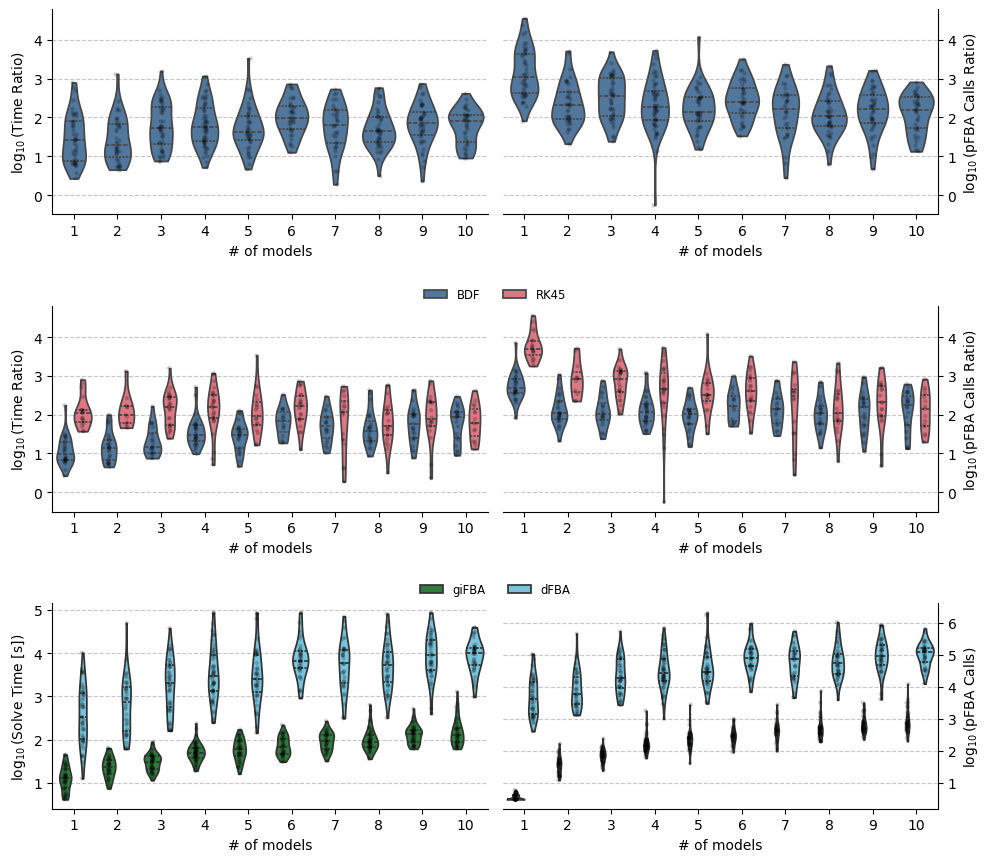

In [5]:
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=tol.bright)

Y_SCALE = "linear"

# Only evaluate groupings whose columns actually exist for this experiment
# (e.g. the N_orgs preset has no y0_factor_binned/y0_offset_binned).
vars_eval = [g for g in bau.VARS_EVAL if all(c in dfba_df.columns for c in g)]

y_min, y_max = (
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].min().min(),
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].max().max(),
)
y_range = y_max - y_min
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

# One extra row at the bottom compares raw giFBA vs. dFBA solve costs.
n_rows = len(vars_eval) + 1
fig, axs = plt.subplots(n_rows, 2, figsize=(10, 3 * n_rows))
axs = axs.flatten()

for row, groupby_cols in enumerate(vars_eval):
    bau.plot_subgrouped(dfba_df, groupby_cols, row, axs, y_min, y_max, y_scale=Y_SCALE)
    
bau.plot_subgrouped(df, ["N_models"], len(vars_eval), axs, y_scale=Y_SCALE, compare_methods=True)

plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3.5)

# Place row legends
for row in range(n_rows):
    ax_left = axs[row * 2]
    ax_right = axs[row * 2 + 1]

    handles, labels = ax_left.get_legend_handles_labels()
    if handles:
        n_subgroups = len(set(labels))
        handles = handles[:n_subgroups]
        labels = labels[:n_subgroups]

        combined_bbox = Bbox.union([ax_left.get_position(), ax_right.get_position()])

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(combined_bbox.x0 + combined_bbox.width / 2, combined_bbox.y1 * 0.99),
            bbox_transform=fig.transFigure,
            ncol=len(handles),
            frameon=False,
            fontsize="small",
        )
        if ax_left.get_legend() is not None:
            ax_left.get_legend().remove()

plt.savefig(FIG_DIR / f"efficiency_violin_plots_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 7. MAE / RPE distributions

12 run(s) had exact-zero MAE; excluded from the log-scale histogram.


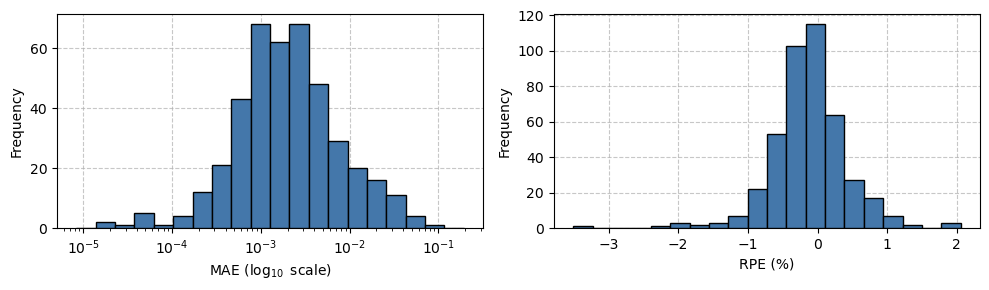

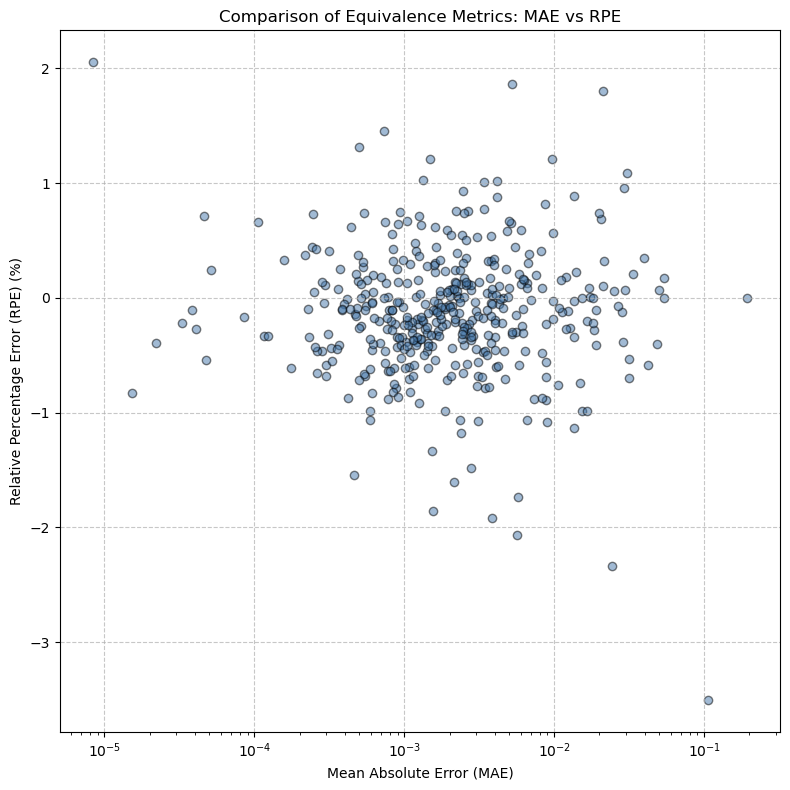

In [ ]:
n_bins = 20

# A run where giFBA and dFBA fluxes match exactly (MAE == 0) has no finite
# log10, so it is left out of the log-scale histogram and percentiles.
mae = eq_df["MAE"]
rpe = eq_df["RPE"]

zero_mae_count = int((mae == 0).sum())
if zero_mae_count:
    print(f"{zero_mae_count} run(s) had exact-zero MAE; excluded from the log-scale histogram.")

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

bin_edges = np.logspace(np.log10(mae[mae > 0].min()), np.log10(mae.max()), n_bins + 1)
axs[0].hist(mae[mae > 0], bins=bin_edges, edgecolor="black", zorder=3)
axs[0].set_xlabel(r"MAE ($\log_{10}$ scale)")
axs[0].set_ylabel("Frequency")
axs[0].set_xscale("log")

axs[1].hist(rpe * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[1].set_xlabel("RPE (%)")
axs[1].set_ylabel("Frequency")

for ax in axs:
    ax.grid(axis="both", linestyle="--", alpha=0.7, zorder=0)
plt.tight_layout()
plt.savefig(FIG_DIR / f"mae_rpe_histograms_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

nonzero_mae = eq_df[eq_df["MAE"] > 0]
plt.figure(figsize=(8, 8))
plt.scatter(nonzero_mae["MAE"], nonzero_mae["RPE"] * 100, alpha=0.5, edgecolor="k")
plt.xscale("log")
plt.xlabel("Mean Absolute Error (MAE)")
plt.ylabel("Relative Percentage Error (RPE) (%)")
plt.title("Comparison of Equivalence Metrics: MAE vs RPE")
plt.grid(axis="both", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(FIG_DIR / f"mae_v_rpe_scatter_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()